In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image    #PIL(biblio pour lire l'image et réagit avec elle)

In [3]:
#Exploration du dataset
dataset_path = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray"

print(os.listdir(dataset_path))



['__MACOSX', 'chest_xray', 'test', 'train', 'val']


In [4]:
# Exploration du dataset
for folder in ["train", "val", "test"]:
    path = os.path.join(dataset_path, folder)
    print(folder, ":", os.listdir(path))

train : ['NORMAL', 'PNEUMONIA']
val : ['NORMAL', 'PNEUMONIA']
test : ['NORMAL', 'PNEUMONIA']


In [5]:
#Exploration de distribution des classes dans le dataset
for folder in ["train", "val", "test"]:
    print(f"\nDataset : {folder}")

    for classe in ["NORMAL", "PNEUMONIA"]:
        class_path = os.path.join(dataset_path, folder, classe)

        images = os.listdir(class_path)

        print(f"{classe} : {len(images)} images")



Dataset : train
NORMAL : 1341 images
PNEUMONIA : 3875 images

Dataset : val
NORMAL : 8 images
PNEUMONIA : 8 images

Dataset : test
NORMAL : 234 images
PNEUMONIA : 390 images


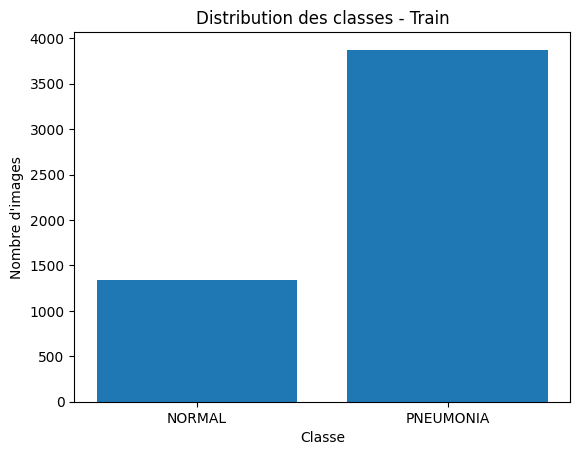

In [6]:
# Visualisation de la distribution des classes
classes = ["NORMAL", "PNEUMONIA"]
counts = [1341, 3875]

plt.bar(classes, counts)
plt.title("Distribution des classes - Train")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()

In [7]:
# Identifier les éventuels problèmes liés aux images
# et gérer les erreurs de chargement

dataset_path = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray"

folders = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]

valid_images = 0
invalid_images = []

for folder in folders:
    for classe in classes:
        class_path = os.path.join(dataset_path, folder, classe)

        for filename in os.listdir(class_path):
            image_path = os.path.join(class_path, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()
                valid_images += 1

            except (OSError, ValueError):
                invalid_images.append(image_path)

print("Images valides :", valid_images)
print("Images invalides :", len(invalid_images))
print("Exemples invalides :", invalid_images[:10])


Images valides : 5856
Images invalides : 0
Exemples invalides : []


### Transforme les imgaes en 180*180 et Format RGB

In [8]:
# Redimensionner une image et la convertir en RGB

image_path = os.path.join(
    dataset_path, "train", "NORMAL",
    os.listdir(os.path.join(dataset_path, "train", "NORMAL"))[0]
)

with Image.open(image_path) as img:
    img_processed = img.convert("RGB").resize((180, 180))

print("Taille :", img_processed.size)
print("Mode :", img_processed.mode)

Taille : (180, 180)
Mode : RGB


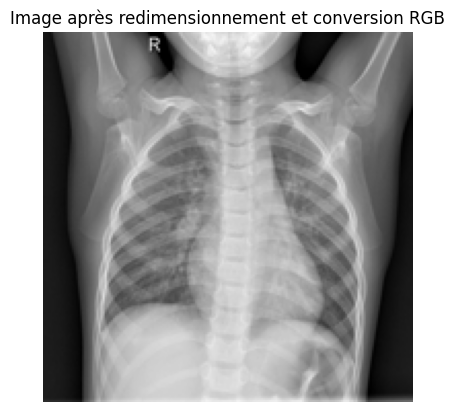

In [9]:
#affiche image aprés la redimension
plt.imshow(img_processed)
plt.title("Image après redimensionnement et conversion RGB")
plt.axis("off")
plt.show()

In [10]:

# Transformer les images en NumPy arrays

import os
import numpy as np
from PIL import Image

folders = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]
image_size = (180, 180)

data = {}

for folder in folders:
    images = []
    labels = []

    for classe in classes:
        class_path = os.path.join(dataset_path, folder, classe)
        label = classes.index(classe)

        for filename in os.listdir(class_path):
            image_path = os.path.join(class_path, filename)

            try:
                with Image.open(image_path) as img:
                    img_processed = img.resize(image_size).convert("RGB")

                    images.append(np.array(img_processed, dtype=np.uint8))
                    labels.append(label)

            except (OSError, ValueError) as e:
                print(f"Image ignorée : {image_path} | Erreur : {e}")

    data[folder] = {
        "images": np.array(images, dtype=np.uint8),
        "labels": np.array(labels, dtype=np.int32)
    }

    print(f"{folder} : {len(images)} images traitées")
    print("Shape des images :", data[folder]["images"].shape)
    print("Shape des labels :", data[folder]["labels"].shape)
    print(labels[:10])

train : 5216 images traitées
Shape des images : (5216, 180, 180, 3)
Shape des labels : (5216,)
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
val : 16 images traitées
Shape des images : (16, 180, 180, 3)
Shape des labels : (16,)
[0, 0, 0, 0, 0, 0, 0, 0, 1, 1]
test : 624 images traitées
Shape des images : (624, 180, 180, 3)
Shape des labels : (624,)
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [11]:
for folder in folders:
    X = data[folder]["images"]
    y = data[folder]["labels"]

    print(f"\n{folder.upper()}")
    print("Type :", X.dtype)
    print("Valeur minimale :", X.min())
    print("Valeur maximale :", X.max())



TRAIN
Type : uint8
Valeur minimale : 0
Valeur maximale : 255

VAL
Type : uint8
Valeur minimale : 0
Valeur maximale : 255

TEST
Type : uint8
Valeur minimale : 0
Valeur maximale : 255


### La normalisation des photos entre (0 et 1)

In [12]:

# Normalisation des pixels dans la plage [0, 1]

X_train = data["train"]["images"].astype(np.float32) / 255.0   #récupérer images train stock in (data) Numpy array
X_val = data["val"]["images"].astype(np.float32) / 255.0
X_test = data["test"]["images"].astype(np.float32) / 255.0
# Vérification de la normalisation
for name, X in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name} :")
    print("Type :", X.dtype)
    print("Min :", X.min())
    print("Max :", X.max())
    print("-" * 30)

Train :
Type : float32
Min : 0.0
Max : 1.0
------------------------------
Validation :
Type : float32
Min : 0.0
Max : 1.0
------------------------------
Test :
Type : float32
Min : 0.0
Max : 1.0
------------------------------


### Affiche échantillon image  de chaque class

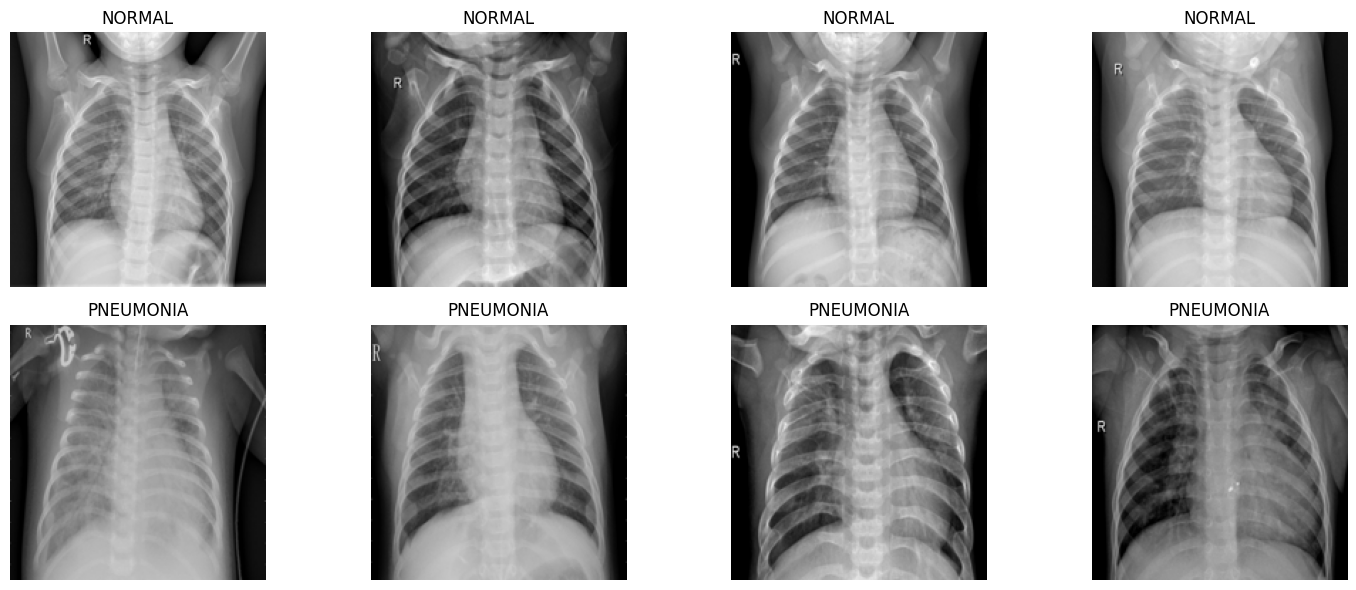

In [13]:
# Noms des classes
classes = ["NORMAL", "PNEUMONIA"]

# Nombre d'images à afficher par classe
n_images = 4

plt.figure(figsize=(15, 6))
y_train = data["train"]["labels"]
for class_id, class_name in enumerate(classes):
    # Récupérer les indices des images de cette classe
    indices = np.where(y_train == class_id)[0][:n_images]

    for i, idx in enumerate(indices):
        plt.subplot(2, n_images, class_id * n_images + i + 1)

        # Afficher l'image
        plt.imshow(X_train[idx])

        # Afficher le nom de la classe
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


### Etude Désiquilibre de class
en trouve que il ya plus de data anormale (PNEUMONIA) par rapport a (NORMAL)
donc pour résolu se probléme je trouve 4 méthode
-Class weights
-Data augmentation
-Oversampling
-Undersampling
et pour notre Cas pour ne pas perdu de data on va appliquer Class weights(nécessite à donner l'importance dans l'error a la class NORMAL)

# **2_Conception du modèle CNN**

In [14]:
from tensorflow import  keras
data_augmentation = keras.Sequential([
    keras.layers.RandomRotation(0.03),
    keras.layers.RandomZoom(0.1),
], name="data_augmentation")

I0000 00:00:1793008938.782942      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793008938.786638      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [15]:
#création de Model
import tensorflow as tf
from tensorflow.keras import layers, models


model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),
    data_augmentation,
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"    #extraire des caractéristiques visuelles.
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    #classification
    layers.Flatten(),    #Transforme les caractéristiques en un vecteur.
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    #binary classification(normal/pneumonia)
    layers.Dense(1, activation="sigmoid")
])


In [16]:
#Compiler le modele CNN
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]
)

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Définition des hyperparamètres
BATCH_SIZE = 32
EPOCHS = 10

### Vérifier la normalisation  (Avant frain modele)

In [19]:
print("Train :", X_train.shape, X_train.dtype)
print("Validation :", X_val.shape, X_val.dtype)
print("Test :", X_test.shape, X_test.dtype)

print("Valeur minimale :", X_train.min())
print("Valeur maximale :", X_train.max())

Train : (5216, 180, 180, 3) float32
Validation : (16, 180, 180, 3) float32
Test : (624, 180, 180, 3) float32
Valeur minimale : 0.0
Valeur maximale : 1.0


In [20]:
#Configurer EarlyStopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,    #check 3epocks befor stopping
    restore_best_weights=True
)

In [21]:
#configurer ReduceLROnPlateau(C’est un mécanisme qui réduit automatiquement le taux d’apprentissage (Learning Rate) lorsque la performance du modèle ne s’améliore plus)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [22]:
#La division de data de train entre train et val(puisque on'a déja suelemnt 16 images dans val pas suffisant pour evaluation de modele)
from sklearn.model_selection import train_test_split

X_train_new, X_val_new, y_train_new, y_val_new = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Train :", X_train_new.shape, y_train_new.shape)
print("Validation :", X_val_new.shape, y_val_new.shape)
print("Test :", X_test.shape, y.shape)

Train : (4694, 180, 180, 3) (4694,)
Validation : (522, 180, 180, 3) (522,)
Test : (624, 180, 180, 3) (624,)


# **3. Entraînement et optimisation du modèle**

In [23]:
#crée l weight
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_new)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_new
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int32(0): np.float64(1.944490472245236), np.int32(1): np.float64(0.6730714080871809)}


Entraîner le CNN avec model.fit

In [24]:
import time

start_time = time.time()

history = model.fit(
    X_train_new,
    y_train_new,
    validation_data=(X_val_new, y_val_new),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping,reduce_lr]
)

end_time = time.time()
training_duration = end_time - start_time

print(f"Durée de l'entraînement : {training_duration:.2f} secondes")
print(f"Nombre d'epochs effectuées : {len(history.history['loss'])}")

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.8157 - auc: 0.9094 - loss: 0.3838 - precision: 0.9335 - recall: 0.8096 - val_accuracy: 0.9215 - val_auc: 0.9904 - val_loss: 0.1900 - val_precision: 0.9915 - val_recall: 0.9021 - learning_rate: 0.0010
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.9152 - auc: 0.9714 - loss: 0.2150 - precision: 0.9722 - recall: 0.9120 - val_accuracy: 0.9483 - val_auc: 0.9912 - val_loss: 0.1218 - val_precision: 0.9813 - val_recall: 0.9485 - learning_rate: 0.0010
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.9242 - auc: 0.9770 - loss: 0.1923 - precision: 0.9754 - recall: 0.9211 - val_accuracy: 0.9061 - val_auc: 0.9911 - val_loss: 0.2417 - val_precision: 0.9913 - val_recall: 0.8814 - learning_rate: 0.0010
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.9359 - auc: 0.9804 - loss: 0.1743 - precision: 0.9772 - recall: 0.9355 - val_accuracy: 0.9674 - val_auc: 0.9927 - val_loss: 0.0963 

Visualiser les courbes d'apprentissage : fonction de perte et métriques de performance.

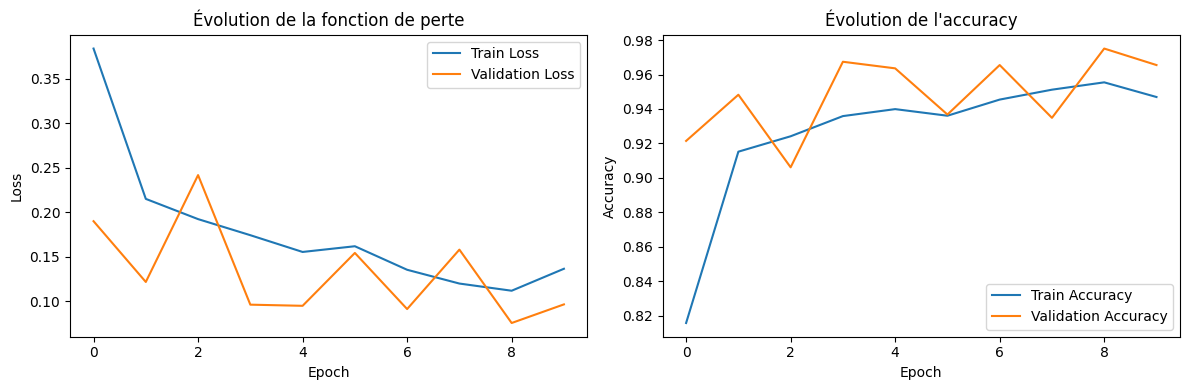

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Évolution de l'accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [26]:
best_epoch = history.history["val_loss"].index(
 min(history.history["val_loss"])
) + 1

print("Meilleure epoch selon val_loss :", best_epoch)
print("Meilleure val_loss :", min(history.history["val_loss"]))
print("Meilleure val_accuracy :", max(history.history["val_accuracy"]))

Meilleure epoch selon val_loss : 9
Meilleure val_loss : 0.07569427043199539
Meilleure val_accuracy : 0.975095808506012


Étudier les effets du déséquilibre des classes et, si nécessaire, utiliser une stratégie de pondération des classes.

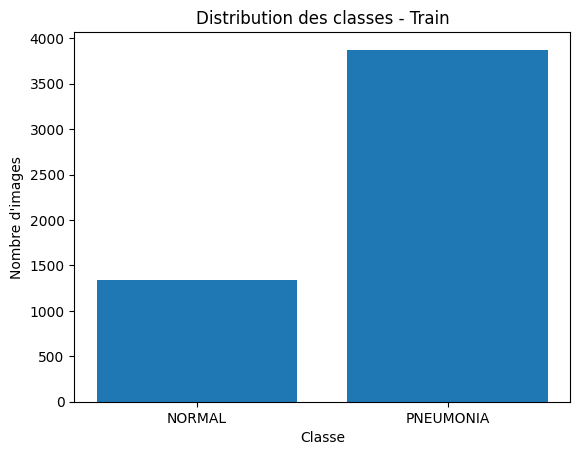

In [27]:
classes = ["NORMAL", "PNEUMONIA"]

plt.bar(classes, counts)
plt.title("Distribution des classes - Train")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()

In [28]:
# Sauvegarder les résultats du premier entraînement (Aprés l'ajoute de Early sttoping et ReduceLROnPlateau)
history_before_weights = history
duration_before_weights = training_duration

print("Résultats du premier entraînement sauvegardés.")
print("Nombre d'epochs :", len(history_before_weights.history["loss"]))
print(f"Durée : {duration_before_weights:.2f} secondes")

Résultats du premier entraînement sauvegardés.
Nombre d'epochs : 10
Durée : 67.17 secondes


Résultats du premier entraînement sauvegardés:
- Nombre d'epochs : 6
- Durée : 40.01 secondes

In [29]:
#Résultats d'entrainement aprées l'ajoute de class_weight
history_with_weights = history
duration_with_weights = training_duration

print("Meilleure val_loss :", min(history.history["val_loss"]))
print("Meilleure val_accuracy :", max(history.history["val_accuracy"]))
print("Nombre d'epochs :", len(history.history["loss"]))
print("Durée :", training_duration, "secondes")

Meilleure val_loss : 0.07569427043199539
Meilleure val_accuracy : 0.975095808506012
Nombre d'epochs : 10
Durée : 67.17016291618347 secondes


Résultats Aprées Ajoute de Weights : 
- Meilleure val_loss : 0.06230515241622925
- Meilleure val_accuracy : 0.9808428883552551
- Nombre d'epochs : 3
- Durée : 21.89597249031067 secondes

# **4. Évaluation du modèle**

Évaluer le modèle sur Test

In [30]:
test_results = model.evaluate(X_test, y, verbose=1)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7869 - auc: 0.9095 - loss: 0.8313 - precision: 0.7515 - recall: 0.9846    


# Analyse de Model Aprés test
Accuracy : environ 83.33 % des images Le modèle a correctement classé.

AUC( 0,9341):Le modèle il a bonne capacité à distinguer les classes NORMAL et PNEUMONIA.

Loss : 0,5977

Precision :Environ 79.18 % des images prédites comme PNEUMONIA sont vraiment dans cette class

Recall : 99,49 % — Le modèle détecte presque tous les cas de PNEUMONIA, avec très peu de faux négatifs.

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


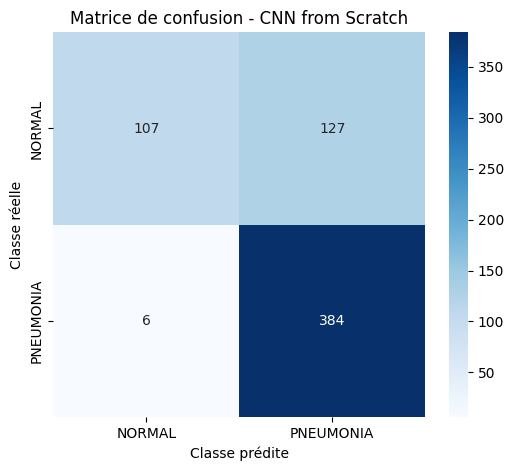

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, model.predict(X_test).round().astype(int))

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion - CNN from Scratch")
plt.show()


Analyse Matrice de Confusion :(P=PNEUMONIA)
    - TN: 132 — Images NORMAL correctement classées.
    - FP: 102 — Images NORMAL classées à tort comme PNEUMONIA.
    - FN: 2 — Images PNEUMONIA classées à tort comme NORMAL
    - TP: 388 — Images PNEUMONIA correctement détectées.



- F1-score : 0,88 — Bon équilibre entre la précision et le rappel pour la classe PNEUMONIA.
- ROC-AUC : 0,956 — Le modèle distingue bien les deux classes selon ses scores de prédiction.

**Comparer les performances obtenues sur les données d'entraînement, de validation et de test.**

In [32]:
print("Train Accuracy :", max(history_with_weights.history["accuracy"]))
print("Validation Accuracy :", max(history_with_weights.history["val_accuracy"]))
print("Test Accuracy :", test_results[1])

Train Accuracy : 0.9554750919342041
Validation Accuracy : 0.975095808506012
Test Accuracy : 0.7868589758872986


# **5. Sauvegarde et utilisation du modèle**

In [33]:
# Sauvegarder le modèle au format .keras
model.save("chestscan_model.keras")

In [34]:
# Sauvegarder la configuration dans un fichier JSON
import json

config = {
    "image_size": [180, 180],
    "class_names": ["NORMAL", "PNEUMONIA"],
    "color_mode": "RGB",
    "normalization": "rescale_1/255",
    "threshold": 0.5      #if score PNEUMONIA >= 0.5 (pictur is PNEUMONIA )
}

with open("config.json", "w") as f:
    json.dump(config, f, indent=4)

In [35]:
#Recharger le modèle sauvegardé(pour voir si en peux réutilise le model sans entrainement)
from tensorflow import keras

loaded_model = keras.models.load_model("chestscan_model.keras")

print("Modèle Loaded .")

Modèle Loaded .


In [36]:
#vérifier i Model Loaded is worked
import numpy as np

image = X_test[0:1]

prediction = loaded_model.predict(image)

score = float(prediction[0][0])
classe = "PNEUMONIA" if score >= 0.5 else "NORMAL"

print("Classe prédite :", classe)
print("Score PNEUMONIA :", round(score, 4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
Classe prédite : PNEUMONIA
Score PNEUMONIA : 0.6456


In [37]:
#Créer la fonction predict_xray(image_path)
from tensorflow import keras
import numpy as np

def predict_xray(image_path):
    img = keras.utils.load_img(
        image_path,
        target_size=(180, 180),
        color_mode="rgb"
    )

    img_array = keras.utils.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)  #augment les dimension de batch

    score = float(loaded_model.predict(img_array, verbose=0)[0][0])

    classe = "PNEUMONIA" if score >= 0.5 else "NORMAL"

    print("Classe prédite :", classe)
    print("Score PNEUMONIA :", round(score, 4))

    return classe, score

# **5. Transfer Learning avec MobileNetV2**

In [38]:
#Vérifier la taille et le type des données d'entrée pour l'entraînement, la validation et le test
print("Train :", X_train_new.shape, X_train_new.dtype)
print("Min / Max :", X_train_new.min(), X_train_new.max())

print("Validation :", X_val_new.shape, X_val_new.dtype)
print("Test :", X_test.shape, X_test.dtype)

Train : (4694, 180, 180, 3) float32
Min / Max : 0.0 1.0
Validation : (522, 180, 180, 3) float32
Test : (624, 180, 180, 3) float32


In [39]:
#normaliser les données d'entrée pour MobileNetV2 Avec (preprocess_input)
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# 1. Redimensionner les images à 224 × 224
X_train_224 = tf.image.resize(X_train_new, (224, 224)).numpy()
X_val_224 = tf.image.resize(X_val_new, (224, 224)).numpy()
X_test_224 = tf.image.resize(X_test, (224, 224)).numpy()

# 2. Adapter les pixels de [0, 1] vers [-1, 1]
X_train_mobilenet = preprocess_input(X_train_224 * 255.0)
X_val_mobilenet = preprocess_input(X_val_224 * 255.0)
X_test_mobilenet = preprocess_input(X_test_224 * 255.0)

# 3. Vérifier les résultats
print("Train :", X_train_mobilenet.shape)
print("Validation :", X_val_mobilenet.shape)
print("Test :", X_test_mobilenet.shape)
print("Min :", X_train_mobilenet.min())
print("Max :", X_train_mobilenet.max())

Train : (4694, 224, 224, 3)
Validation : (522, 224, 224, 3)
Test : (624, 224, 224, 3)
Min : -1.0
Max : 1.0


Charger MobileNetV2 préentraîné sur ImageNet

In [40]:
from tensorflow import keras

base_model = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("MobileNetV2 Done")
print("Nombre de couches :", len(base_model.layers))    #154 couches
print("Nombre total de paramètres :", base_model.count_params())

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 Done
Nombre de couches : 154
Nombre total de paramètres : 2257984


In [41]:
# Geler toutes les couches de MobileNetV2
base_model.trainable = False

Ajouter la tête de classification

In [42]:
from tensorflow import keras

# Entrée des images
inputs = keras.Input(shape=(224, 224, 3))

# Extraction des caractéristiques avec MobileNetV2
x = base_model(inputs, training=False)

# Transformer les caractéristiques à un vecteur
x = keras.layers.GlobalAveragePooling2D()(x)

# Classification binaire
outputs = keras.layers.Dense(1, activation="sigmoid")(x)

# Construire le modèle complet
model_mobilenet = keras.Model(inputs, outputs)

model_mobilenet.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [43]:
#copiler le modele MobileNetV2
from tensorflow import keras

model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

In [44]:
#Entrainer seulemenet les couches que on'a ajouter de classification 
from tensorflow import keras

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3, #check 3epocks befor stopping
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    patience=2,
    min_lr=1e-6   #min_lr=0.00001
)

history_mobilenet = model_mobilenet.fit(
    X_train_mobilenet,
    y_train_new,
    validation_data=(X_val_mobilenet, y_val_new),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr]
)

print("Meilleure val_loss :", min(history_mobilenet.history["val_loss"]))
print("Meilleure val_accuracy :", max(history_mobilenet.history["val_accuracy"]))
print("Meilleure epoch :", history_mobilenet.history["val_loss"].index(min(history_mobilenet.history["val_loss"])) + 1)

Epoch 1/15


2026-10-26 10:04:12.163407: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:04:12.300841: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793009054.239799     144 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


145/147 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8773 - auc: 0.9487 - loss: 0.2953 - precision: 0.8734 - recall: 0.9804

2026-10-26 10:04:27.232007: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:04:27.368927: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.8779 - auc: 0.9491 - loss: 0.2943 - precision: 0.8741 - recall: 0.9803

2026-10-26 10:04:43.314572: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:04:43.450977: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


147/147 ━━━━━━━━━━━━━━━━━━━━ 47s 213ms/step - accuracy: 0.9178 - auc: 0.9724 - loss: 0.2186 - precision: 0.9198 - recall: 0.9742 - val_accuracy: 0.9693 - val_auc: 0.9909 - val_loss: 0.1348 - val_precision: 0.9769 - val_recall: 0.9820 - learning_rate: 0.0010
Epoch 2/15
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9578 - auc: 0.9904 - loss: 0.1255 - precision: 0.9684 - recall: 0.9751 - val_accuracy: 0.9636 - val_auc: 0.9915 - val_loss: 0.1112 - val_precision: 0.9601 - val_recall: 0.9923 - learning_rate: 0.0010
Epoch 3/15
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9634 - auc: 0.9931 - loss: 0.1040 - precision: 0.9737 - recall: 0.9771 - val_accuracy: 0.9751 - val_auc: 0.9939 - val_loss: 0.0953 - val_precision: 0.9870 - val_recall: 0.9794 - learning_rate: 0.0010
Epoch 4/15
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9683 - auc: 0.9944 - loss: 0.0921 - precision: 0.9777 - recall: 0.9796 - val_accuracy: 0.9789 - val_auc: 0.9927 - val_loss: 0.0842 - val_prec

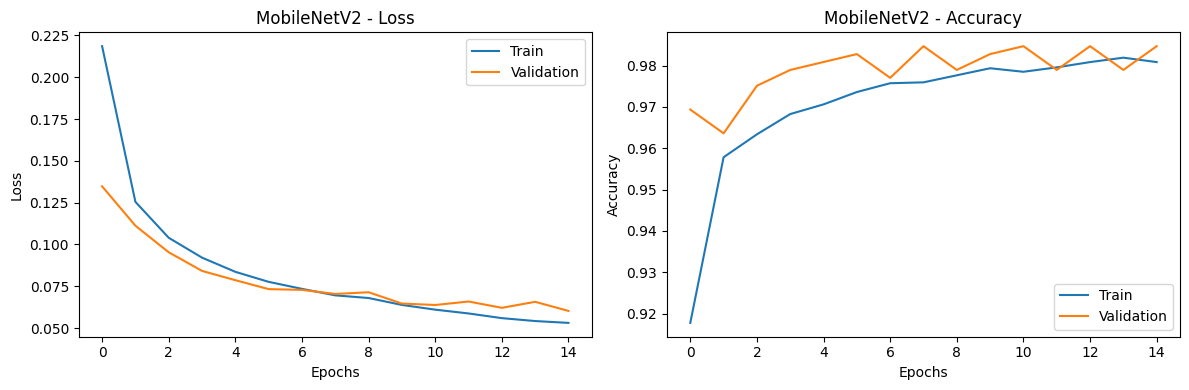

In [45]:
import matplotlib.pyplot as plt

# Récupérer les résultats de l'entraînement
history = history_mobilenet.history

# Courbes d'apprentissage
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")
plt.title("MobileNetV2 - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["accuracy"], label="Train")
plt.plot(history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

Analyse des  courbes 
 - Loss : loss Train  diminue progressivement, tandis que loss validation  reste stable, indiquant un apprentissage régulier.
 - Accuracy : L’accuracy atteint environ 97,45 % en entraînement et 98,6 % en validation, Bon performances.

Évaluer le modèle sur (test(624images) data que le Model pas encore utiliser ): Accuracy, Precision, Recall, AUC et matrice de confusion

In [46]:

# Évaluation du modèle MobileNetV2 sur le jeu de test

test_results = model_mobilenet.evaluate(
    X_test_mobilenet,
    y,
    return_dict=True
)

print("\nEvaluation Model sur test data  :")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")
    
    

# Evaluation Model sur test data  :
# accuracy: 0.8221 
# auc: 0.9429
# loss: 0.5094
# precision: 0.7796 
# recall: 0.9974  (99% des cas de pneumonie sont correctement identifiés)
#(accuracy 88% et precision 77% (signifie que il ya des cas normal prédit))


19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6895 - auc: 0.5949 - loss: 1.0068 - precision: 0.3725 - recall: 0.6243  

2026-10-26 10:06:04.467698: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:06:04.604313: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 10:06:04.740628: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 562ms/step - accuracy: 0.8285 - auc: 0.9454 - loss: 0.5583 - precision: 0.7870 - recall: 0.9949

Evaluation Model sur test data  :
accuracy: 0.8285
auc: 0.9454
loss: 0.5583
precision: 0.7870
recall: 0.9949


Matric de Confusion(how much prédiction correct/false)

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 239ms/step


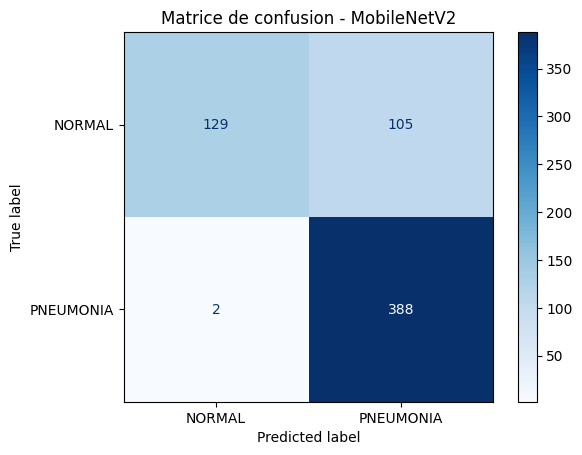

In [47]:
#   Matrice de confusion pour le modèle MobileNetV2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

y_prob = model_mobilenet.predict(X_test_mobilenet).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - MobileNetV2")
plt.show()


In [48]:
model_mobilenet.save("mobilenetv2_transfer.keras")

### 6. Fine-tuning de MobileNetV2

In [49]:
# Débloquer une partie des dernières couches
base_model.trainable = True

# Garder les premières couches gelées
fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Vérifier les couches entraînables
trainable_layers = sum(
    layer.trainable for layer in base_model.layers
)

print("Nombre total de couches :", len(base_model.layers))
print("Couches entraînables :", trainable_layers)
print("Couches gelées :", len(base_model.layers) - trainable_layers)


Nombre total de couches : 154
Couches entraînables : 54
Couches gelées : 100


In [50]:
# Recompiler le modèle pour le fine-tuning

model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)


In [51]:
# Poursuivre l’entraînement avec le Fine-tuning

early_stopping_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr_ft = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    patience=2,
    min_lr=1e-7
)

# Entraînement du modèle après fine-tuning

history_finetuning = model_mobilenet.fit(
    X_train_mobilenet,
    y_train_new,
    validation_data=(X_val_mobilenet, y_val_new),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping_ft, reduce_lr_ft]
)


Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 44s 170ms/step - accuracy: 0.9152 - auc: 0.9644 - loss: 0.2361 - precision: 0.9216 - recall: 0.9682 - val_accuracy: 0.9636 - val_auc: 0.9949 - val_loss: 0.1123 - val_precision: 0.9533 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9691 - auc: 0.9942 - loss: 0.0822 - precision: 0.9796 - recall: 0.9788 - val_accuracy: 0.9751 - val_auc: 0.9913 - val_loss: 0.0931 - val_precision: 0.9676 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9821 - auc: 0.9974 - loss: 0.0537 - precision: 0.9888 - recall: 0.9871 - val_accuracy: 0.9732 - val_auc: 0.9913 - val_loss: 0.0900 - val_precision: 0.9675 - val_recall: 0.9974 - learning_rate: 1.0000e-05
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9862 - auc: 0.9991 - loss: 0.0360 - precision: 0.9908 - recall: 0.9905 - val_accuracy: 0.9770 - val_auc: 0.9913 - val_

In [52]:
# Enregistrer le modèle après Fine-tuning
model_mobilenet.save("mobilenetv2_finetuned.keras")

In [53]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

def evaluer_modele(nom, modele, X_test_modele, y_true):
    y_proba = modele.predict(X_test_modele, verbose=0).ravel()
    y_pred = (y_proba >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Loss": modele.evaluate(
            X_test_modele, y_true, verbose=0, return_dict=True
        )["loss"],
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Loss,TN,FP,FN,TP
Modèle,,,,,,,,,,
CNN from Scratch,0.7869,0.7515,0.9846,0.8524,0.9504,0.8313,107,127,6,384
MobileNetV2 - Transfer Learning,0.8285,0.7870,0.9949,0.8788,0.9582,0.5583,129,105,2,388
MobileNetV2 - Fine-tuning,0.8189,0.7776,0.9949,0.8729,0.9667,0.7665,123,111,2,388


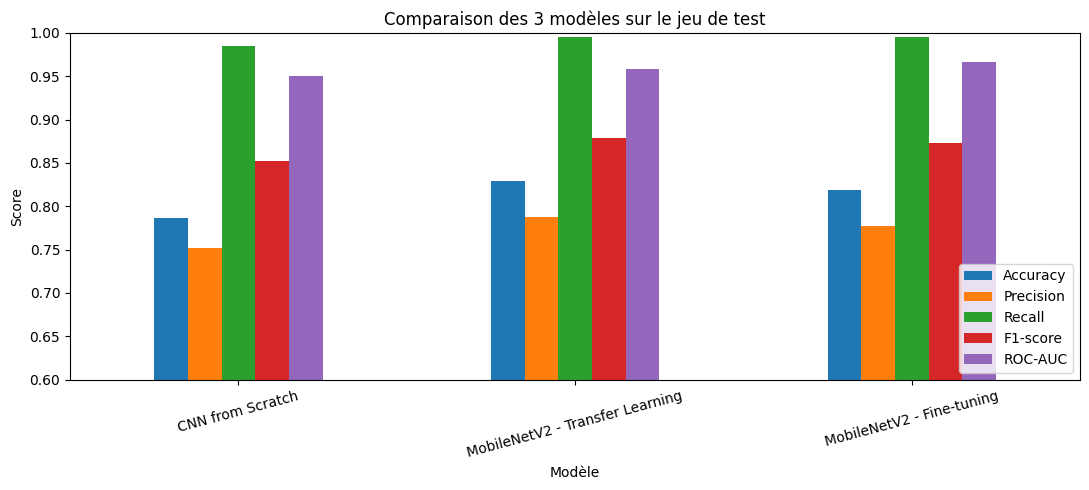

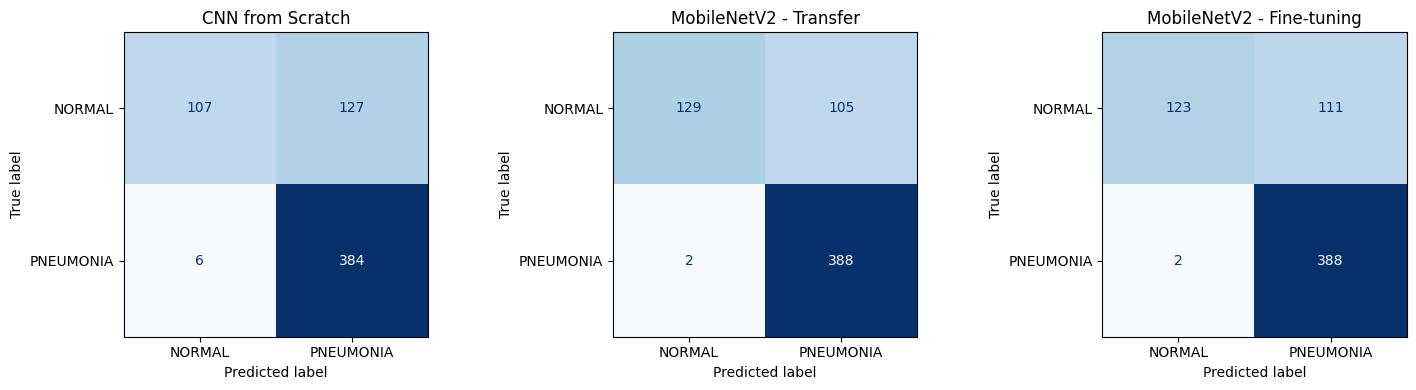

In [54]:
from tensorflow import keras
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Labels du test (au lieu de la variable `y`, qui dépend de la dernière boucle exécutée)
y_test = data["test"]["labels"]

# Recharger les deux versions distinctes de MobileNetV2
model_transfer  = keras.models.load_model("mobilenetv2_transfer.keras")
model_finetuned = keras.models.load_model("mobilenetv2_finetuned.keras")

# Évaluation des 3 modèles
resultats = [
    evaluer_modele("CNN from Scratch", model, X_test, y_test),
    evaluer_modele("MobileNetV2 - Transfer Learning", model_transfer, X_test_mobilenet, y_test),
    evaluer_modele("MobileNetV2 - Fine-tuning", model_finetuned, X_test_mobilenet, y_test),
]

df_resultats = pd.DataFrame(resultats).set_index("Modèle")
display(df_resultats.round(4))

# Graphique comparatif des métriques
metriques = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
df_resultats[metriques].plot(kind="bar", figsize=(11, 5))
plt.title("Comparaison des 3 modèles sur le jeu de test")
plt.ylabel("Score")
plt.ylim(0.6, 1.0)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Matrices de confusion côte à côte
modeles = [
    ("CNN from Scratch", model, X_test),
    ("MobileNetV2 - Transfer", model_transfer, X_test_mobilenet),
    ("MobileNetV2 - Fine-tuning", model_finetuned, X_test_mobilenet),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, m, X) in zip(axes, modeles):
    y_pred = (m.predict(X, verbose=0).ravel() >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["NORMAL", "PNEUMONIA"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(nom)
plt.tight_layout()
plt.show()

8. Sauvegarde et utilisation du modèle

In [55]:
import json
from tensorflow import keras

# Sauvegarder le meilleur modèle (MobileNetV2 - Transfer Learning)
model_transfer.save("best_model_mobilenetv2.keras")

# Sauvegarder les paramètres de prétraitement
config = {
    "model_name": "MobileNetV2 - Transfer Learning",
    "model_file": "best_model_mobilenetv2.keras",
    "image_size": [224, 224],
    "class_names": ["NORMAL", "PNEUMONIA"],
    "color_mode": "RGB",
    "preprocessing": "tensorflow.keras.applications.mobilenet_v2.preprocess_input (pixels [0,255] -> [-1,1])",
    "threshold": 0.5   # score PNEUMONIA >= 0.5 -> PNEUMONIA
}

with open("config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Modèle et configuration sauvegardés.")

Modèle et configuration sauvegardés.


In [56]:
import json
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Recharger la configuration et le modèle retenu
with open("config.json") as f:
    config = json.load(f)

best_model = keras.models.load_model(config["model_file"])
print("Modèle rechargé :", config["model_name"])

def predict_xray(image_path, show=True):
    # 1. Charger l'image en RGB et la redimensionner
    img = keras.utils.load_img(
        image_path,
        target_size=tuple(config["image_size"]),
        color_mode="rgb"
    )

    # 2. Prétraitement MobileNetV2 (attend des pixels 0-255)
    img_array = keras.utils.img_to_array(img)
    img_array = preprocess_input(img_array)
    img_array = np.expand_dims(img_array, axis=0)

    # 3. Prédiction
    score = float(best_model.predict(img_array, verbose=0)[0][0])
    classe = config["class_names"][int(score >= config["threshold"])]

    print(f"Classe prédite : {classe}")
    print(f"Score PNEUMONIA : {score:.4f}")

    if show:
        plt.imshow(img)
        plt.title(f"{classe} (score PNEUMONIA = {score:.2f})")
        plt.axis("off")
        plt.show()

    return classe, score

Modèle rechargé : MobileNetV2 - Transfer Learning
